# 12 — Avaliação nas sessões de teste: H1, H2 e comparação com a regra de limiar

Usa **somente** as sessões com `papel = teste` no `sessoes.csv`, que não participaram do treino nem da validação (notebook 11). A unidade de avaliação é a **decisão de 10 s**, como no firmware.

**Abordagens comparadas** (mesmas decisões, mesmos rótulos):

| Abordagem | Como decide |
|---|---|
| **Multimodal (fusão treinada)** | camada densa sobre as probabilidades do LSTM e da CNN int8 (como embarcado) |
| Multimodal (fusão por regra) | Figura 5 sobre o nível térmico do LSTM e o nível acústico da CNN |
| Unimodal LSTM | só o ramo ambiental: classe = Figura 5 (nível térmico do LSTM, acústico 0) |
| Unimodal CNN | só o ramo acústico: classe = Figura 5 (térmico 0, nível acústico da CNN) |
| Regra de limiar térmico | limiares de 27, 32 e 35 °C sobre o BME280 no último passo (objetivo e) |

**Critérios** (seção 1): H1 — F1-score macro do multimodal **superior** ao do melhor unimodal; H2 — acurácia > 90%, F1 macro ≥ 0,80 e recall da classe Falha ≥ 0,85 (latência e memória são medidas na placa, Tabela 12).

Para dar a dimensão da incerteza, as diferenças de F1 macro vêm com **intervalo de confiança de 95% por bootstrap de eventos** (reamostra eventos inteiros, porque decisões do mesmo evento não são independentes).

In [1]:
# 1. Ambiente e caminhos
import os, sys, json, subprocess, importlib.util
if importlib.util.find_spec("tensorflow") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow"], check=True)
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
from sklearn.metrics import f1_score, accuracy_score, precision_recall_fscore_support, confusion_matrix, roc_auc_score, roc_curve
try:
    from IPython.display import display
except ImportError:
    display = print
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml")
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter
CONJUNTO = os.environ.get("CONJUNTO_TINYML", "coleta_sim")   # "coleta_sim" = sessões sintéticas (notebook 07b) | "coleta" = dados do nó
CONJUNTO = "coleta_sim"
SIM = CONJUNTO != "coleta"
print("Conjunto de dados:", CONJUNTO)
DISS = f"{BASE}/dissertacao_cap9" + ("_sim" if SIM else ""); os.makedirs(DISS, exist_ok=True)   # figuras e tabelas que vão para o texto
COLETA, ROT, MOD = f"{BASE}/{CONJUNTO}", f"{BASE}/{CONJUNTO}/rotulado", f"{BASE}/modelos/" + ("sim" if SIM else "insitu")
SAIDA = f"{BASE}/" + ("resultados_sim" if SIM else "resultados_insitu"); os.makedirs(SAIDA, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.titlesize": 10.5, "savefig.dpi": 300, "savefig.bbox": "tight"})
N_BOOT = 2000

Mounted at /content/drive
Conjunto de dados: coleta_sim


In [2]:
# 2. Rótulos e matriz da Figura 5 (iguais aos dos notebooks 10 e 11)
# ===== Rotulação das sessões de eventos (seção 3.3.1 e Figura 5) =====
TIPOS = ["termico", "desbalanceamento", "obstrucao", "combinado"]
ACUSTICOS = {"desbalanceamento", "obstrucao", "combinado"}     # o tipo térmico não altera o nível acústico
TERMICOS = {"termico", "combinado"}
NOMES_CLASSE = ["Normal", "Atenção", "Crítico", "Falha"]

def classe_termica(t):
    t = np.asarray(t, dtype=float)
    return np.select([t > 35.0, t > 32.0, t > 27.0], [3, 2, 1], 0)

def classe_fusao_regra(nt, na):
    """Figura 5: prevalece o mais severo; térmico 2 com acústico >= 1 vira Falha; nível 3 em qualquer ramo = Falha."""
    nt, na = np.asarray(nt), np.asarray(na)
    c = np.maximum(nt, na)
    c = np.where((nt == 2) & (na >= 1), 3, c)
    return np.where((nt == 3) | (na == 3), 3, c).astype(int)

def eventos_da_sessao(evt, planilha, sessao):
    """Junta os pares início/fim do EVT.CSV com a planilha (tipo, nível, fundo) pelo número do evento."""
    e = evt[evt.evento > 0]
    ini = e[e.tipo == "inicio"].set_index("evento").amostra
    fim = e[e.tipo == "fim"].set_index("evento").amostra
    ev = pd.DataFrame({"amostra_ini": ini, "amostra_fim": fim}).reset_index()
    p = planilha[planilha.sessao == sessao].copy()
    problemas = []
    if ev.amostra_fim.isna().any():
        problemas.append(f"eventos sem fim no EVT.CSV: {ev[ev.amostra_fim.isna()].evento.tolist()}")
    if len(ev) != len(p):
        problemas.append(f"EVT.CSV tem {len(ev)} eventos e a planilha tem {len(p)} para {sessao}")
    ev = ev.merge(p[["evento", "tipo", "nivel", "fundo"]], on="evento", how="left")
    if ev.tipo.isna().any():
        problemas.append(f"eventos sem linha na planilha: {ev[ev.tipo.isna()].evento.tolist()}")
    return ev, problemas

def rotulos_acusticos(n_jan, ev, fs, transicao_s):
    """Nível acústico de cada janela de 1 s: nível do evento (tipos acústicos) ou 0; -1 = janela descartada
    por estar a menos de transicao_s de uma marcação. Também devolve o número do evento de cada janela (0 = fora)."""
    ini = np.arange(n_jan) * fs; fim = ini + fs
    y = np.zeros(n_jan, int); evid = np.zeros(n_jan, int)
    marg = int(transicao_s * fs)
    for _, e in ev.iterrows():
        a, b = int(e.amostra_ini), int(e.amostra_fim)
        dentro = (ini >= a) & (fim <= b)
        evid[dentro] = e.evento
        if e.tipo in ACUSTICOS: y[dentro] = int(e.nivel)
        for m in (a, b):                                   # janelas perto de uma marcação
            y[(fim > m - marg) & (ini < m + marg)] = -1
    return y, evid

def referencia_10s(termo, inicio_real, blocos, offset_s=0.0, max_lacuna_s=60):
    """Temperatura do termo-higrômetro interpolada na grade de 10 s do áudio (NaN onde não há referência)."""
    if termo is None or not len(termo):
        return np.full(len(blocos), np.nan)
    s = (pd.to_datetime(termo.horario) - pd.Timestamp(inicio_real)).dt.total_seconds().values + offset_s
    t = termo.temp_ref.values.astype(float)
    ordem = np.argsort(s); s, t = s[ordem], t[ordem]
    grade = np.asarray(blocos) * 10.0 + 5.0                # centro de cada bloco de 10 s do áudio
    ref = np.interp(grade, s, t, left=np.nan, right=np.nan)
    pos = np.searchsorted(s, grade)
    viz = np.minimum(np.abs(grade - s[np.clip(pos - 1, 0, len(s) - 1)]), np.abs(s[np.clip(pos, 0, len(s) - 1)] - grade))
    ref[viz > max_lacuna_s] = np.nan                        # longe de qualquer leitura: sem referência
    return ref


In [3]:
# 3. Modelos in situ e sessões de teste
q = json.load(open(f"{MOD}/cnn_insitu_quantizacao.json"))
MU, SD = np.array(q["linha_de_base"]["media"], np.float32), np.array(q["linha_de_base"]["desvio"], np.float32)
it = Interpreter(model_content=open(f"{MOD}/cnn_insitu_int8.tflite", "rb").read()); it.allocate_tensors()
e_, s_ = it.get_input_details()[0], it.get_output_details()[0]
(se, ze), (ss, zs) = e_["quantization"], s_["quantization"]
lstm = tf.keras.models.load_model(f"{MOD}/lstm_insitu.keras")
fz = json.load(open(f"{MOD}/fusao.json")); W, Bf = np.array(fz["W"]), np.array(fz["b"])
FAIXAS = {"temp": (10.0, 45.0), "umid": (0.0, 100.0), "dpress": (-5.0, 5.0)}
def atributos(v):
    v = np.asarray(v, np.float32); dp = v[..., 2] - v[..., 2].mean(axis=-1, keepdims=True)
    cols = [v[..., 0], v[..., 1], dp]
    return np.stack([np.clip((c - lo) / (hi - lo), 0, 1) for c, (lo, hi) in zip(cols, FAIXAS.values())], -1).astype(np.float32)
def cnn_int8(Xraw):
    out = np.zeros((len(Xraw), 4), np.float32)
    zz = (Xraw.astype(np.float32) - MU) / SD
    for i in range(len(zz)):
        it.set_tensor(e_["index"], np.clip(np.round(zz[i:i + 1, ..., None] / se + ze), -128, 127).astype(np.int8)); it.invoke()
        out[i] = (it.get_tensor(s_["index"])[0].astype(np.float32) - zs) * ss
    return out
def softmax(a): a = a - a.max(1, keepdims=True); e = np.exp(a); return e / e.sum(1, keepdims=True)

SESSOES = pd.read_csv(f"{COLETA}/sessoes.csv", dtype=str).fillna("")
TESTE = SESSOES[SESSOES.papel == "teste"].sessao.tolist()
if SIM:   # proteção: com o conjunto sintético, só entram sessões geradas pelo 07b (SIMnnn)
    _fora = [s for s in SESSOES.sessao if not str(s).startswith("SIM")]
    assert not _fora, f"sessoes.csv de {CONJUNTO} contém sessões que não são do 07b: {_fora}"
print("Sessões lidas:", SESSOES.sessao.tolist())
assert TESTE, "Nenhuma sessão com papel = teste no sessoes.csv"
treino_usado = set(q["sessoes"]); assert not treino_usado & set(TESTE), "Sessão de teste usada no treino!"
print("Sessões de teste:", TESTE)

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Sessões lidas: ['SIM001', 'SIM002', 'SIM003', 'SIM004', 'SIM005', 'SIM006']
Sessões de teste: ['SIM006']


In [4]:
# 4. Predições de todas as abordagens nas decisões de 10 s
linhas = []
for s in TESTE:
    d = dict(np.load(f"{ROT}/{s}.npz"))
    if not len(d["dec_y"]): print("Sem decisões:", s); continue
    jan = np.unique(np.concatenate([np.arange(j - 9, j + 1) for j in d["dec_j"]]))
    pc = np.zeros((len(d["ya"]), 4), np.float32); pc[jan] = cnn_int8(d["Xc"][jan])
    pc10 = np.stack([pc[j - 9:j + 1].mean(0) for j in d["dec_j"]])
    Xw = d["Xl"][d["dec_l"]]
    pl = lstm.predict(atributos(Xw), batch_size=256, verbose=0)
    pf = softmax(np.concatenate([pl, pc10], 1) @ W + Bf)
    nt, na = pl.argmax(1), pc10.argmax(1)
    df = pd.DataFrame({"sessao": s, "evento": d["dec_ev"], "y": d["dec_y"], "y_term": d["dec_yt"], "y_ac": d["dec_ya"],
                       "multimodal": pf.argmax(1), "fusao_regra": classe_fusao_regra(nt, na),
                       "lstm": classe_fusao_regra(nt, 0), "cnn": classe_fusao_regra(0, na),
                       "regra_limiar": classe_fusao_regra(classe_termica(Xw[:, -1, 0]), 0)})
    for c in range(4): df[f"p{c}"] = pf[:, c]
    # grupo para o bootstrap: cada evento, e cada trecho fora de evento entre dois eventos, é um grupo
    ult, g = 0, []
    for e in df.evento.values:
        if e > 0: ult = e; g.append(f"{s}_ev{e}")
        else: g.append(f"{s}_apos{ult}")
    df["grupo"] = g
    linhas.append(df)
R = pd.concat(linhas, ignore_index=True); R.to_csv(f"{SAIDA}/predicoes_teste.csv", index=False)
print("Decisões de teste por classe:", np.bincount(R.y, minlength=4))

Decisões de teste por classe: [1146  436  193  223]


In [5]:
# 5. Métricas por abordagem (H1, H2 e objetivo e)
ABORD = {"multimodal": "Multimodal (fusão treinada)", "fusao_regra": "Multimodal (fusão por regra)",
         "lstm": "Unimodal LSTM", "cnn": "Unimodal CNN", "regra_limiar": "Regra de limiar térmico"}
def metricas(y, p):
    pr, rc, f1, _ = precision_recall_fscore_support(y, p, labels=[0, 1, 2, 3], zero_division=0)
    m = {"acuracia": accuracy_score(y, p), "f1_macro": f1_score(y, p, labels=[0, 1, 2, 3], average="macro", zero_division=0)}
    for c in range(4): m.update({f"precisao_{NOMES_CLASSE[c]}": pr[c], f"recall_{NOMES_CLASSE[c]}": rc[c], f"f1_{NOMES_CLASSE[c]}": f1[c]})
    return m
M = pd.DataFrame({k: metricas(R.y, R[k]) for k in ABORD}).T
M.index = [ABORD[k] for k in M.index]
M.to_csv(f"{SAIDA}/metricas_teste.csv")
display(M[["acuracia", "f1_macro", "recall_Falha"]].round(4))

melhor_uni = max(["lstm", "cnn"], key=lambda k: f1_score(R.y, R[k], average="macro", labels=[0, 1, 2, 3], zero_division=0))
mm = M.loc[ABORD["multimodal"]]
H = {"H1_multimodal_f1": mm.f1_macro, "H1_melhor_unimodal": ABORD[melhor_uni],
     "H1_melhor_unimodal_f1": M.loc[ABORD[melhor_uni]].f1_macro, "H1_atende": bool(mm.f1_macro > M.loc[ABORD[melhor_uni]].f1_macro),
     "H2_acuracia": mm.acuracia, "H2_f1_macro": mm.f1_macro, "H2_recall_falha": mm.recall_Falha,
     "H2_atende_metricas": bool(mm.acuracia > 0.90 and mm.f1_macro >= 0.80 and mm.recall_Falha >= 0.85)}
print(json.dumps(H, indent=1, ensure_ascii=False, default=float))

,acuracia,f1_macro,recall_Falha
Multimodal (fusão treinada),0.9309,0.9211,0.9641
Multimodal (fusão por regra),0.8834,0.8892,0.9552
Unimodal LSTM,0.7808,0.6149,0.2960
Unimodal CNN,0.7102,0.6732,0.6547
Regra de limiar térmico,0.7613,0.5844,0.3184


{
 "H1_multimodal_f1": 0.921145576553805,
 "H1_melhor_unimodal": "Unimodal CNN",
 "H1_melhor_unimodal_f1": 0.6732457465903374,
 "H1_atende": true,
 "H2_acuracia": 0.9309309309309309,
 "H2_f1_macro": 0.921145576553805,
 "H2_recall_falha": 0.9641255605381166,
 "H2_atende_metricas": true
}


In [9]:
# 5b. LSTM contra o rótulo térmico (para comparar com a validação)
from sklearn.metrics import f1_score, recall_score
m = R.y_term >= 0          # ignora janelas sem rótulo térmico, se houver
print("Decisões consideradas:", int(m.sum()), "de", len(R))
print("F1 macro LSTM x rótulo térmico:",
      round(f1_score(R.y_term[m], R.lstm[m], labels=[0,1,2,3], average="macro", zero_division=0), 4))
print("F1 macro LSTM x rótulo final (Tabela 13):",
      round(f1_score(R.y, R.lstm, labels=[0,1,2,3], average="macro", zero_division=0), 4))
print("Recall por nível térmico:",
      recall_score(R.y_term[m], R.lstm[m], labels=[0,1,2,3], average=None, zero_division=0).round(3))
print("Decisões por nível térmico:", np.bincount(R.y_term[m], minlength=4))

Decisões consideradas: 1998 de 1998
F1 macro LSTM x rótulo térmico: 0.9568
F1 macro LSTM x rótulo final (Tabela 13): 0.6149
Recall por nível térmico: [0.979 0.994 0.933 0.93 ]
Decisões por nível térmico: [1489  349   89   71]


In [6]:
# 6. Intervalos de confiança de 95% (bootstrap por evento) para as diferenças de F1 macro
grupos = R.grupo.values
ug = np.unique(grupos); idx_g = {g: np.where(grupos == g)[0] for g in ug}
rng = np.random.default_rng(0)
f1m = lambda y, p: f1_score(y, p, labels=[0, 1, 2, 3], average="macro", zero_division=0)
comparacoes = [("multimodal", melhor_uni), ("multimodal", "regra_limiar"), ("multimodal", "fusao_regra")]
dif = {c: [] for c in comparacoes}
for _ in range(N_BOOT):
    sel = np.concatenate([idx_g[g] for g in rng.choice(ug, len(ug), replace=True)])
    y = R.y.values[sel]
    for a, b in comparacoes: dif[(a, b)].append(f1m(y, R[a].values[sel]) - f1m(y, R[b].values[sel]))
IC = pd.DataFrame([{"comparacao": f"{ABORD[a]} − {ABORD[b]}", "diferenca_f1_macro": f1m(R.y, R[a]) - f1m(R.y, R[b]),
                    "ic95_inf": np.percentile(dif[(a, b)], 2.5), "ic95_sup": np.percentile(dif[(a, b)], 97.5)} for a, b in comparacoes])
IC.to_csv(f"{SAIDA}/ic_bootstrap.csv", index=False); display(IC.round(4))
print(f"Grupos reamostrados: {len(ug)} (eventos e trechos entre eventos)")

,comparacao,diferenca_f1_macro,ic95_inf,ic95_sup
0,Multimodal (fusão treinada) − Unimodal CNN,0.2479,0.1307,0.4574
1,Multimodal (fusão treinada) − Regra de limiar ...,0.3368,0.1987,0.4597
2,Multimodal (fusão treinada) − Multimodal (fusã...,0.0319,-0.0172,0.0786


Grupos reamostrados: 25 (eventos e trechos entre eventos)


### ➜ DISSERTAÇÃO — Figura da seção 9.4

Matrizes de confusão no teste: (a) multimodal (fusão treinada), (b) unimodal LSTM, (c) unimodal CNN, (d) regra de limiar térmico. A curva ROC (segunda figura da célula) é opcional: a AUC macro pode ir só no texto.

Título sugerido: *Matrizes de confusão das abordagens no conjunto de teste*. Nota: sessões sintéticas (seção 9.1); valores por decisão de 10 s e porcentagem por linha (recall).

Arquivo: `Figura_9_4_matrizes.png / .svg (e Figura_9_4_roc_opcional.png)` na pasta `dissertacao_cap9_sim/` (ou `dissertacao_cap9/` com dados do nó). No Word: rótulo com `SEQ Figura`, título em itálico e a nota indicada abaixo.

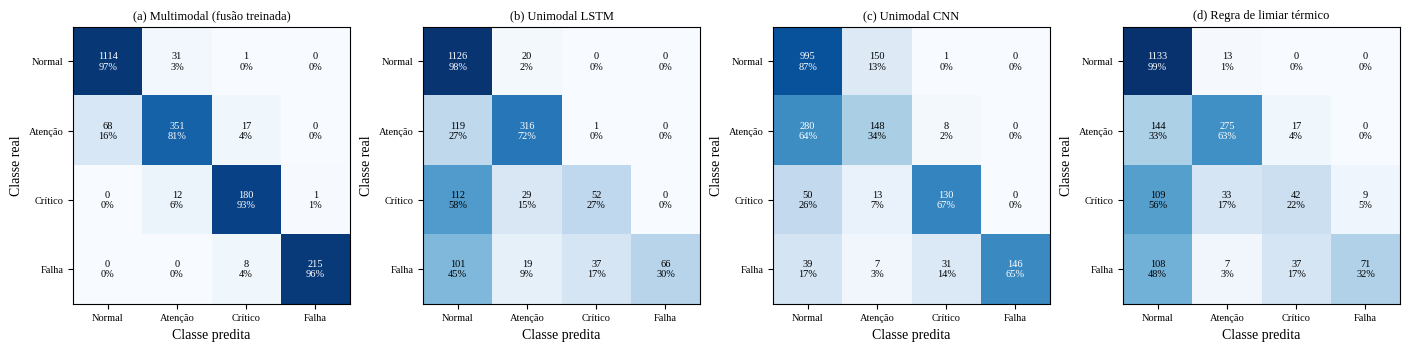

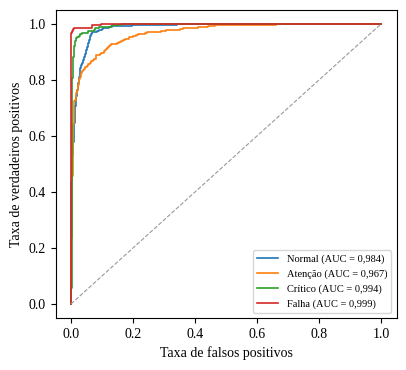

AUC macro (um-contra-todos): 0.9857523919442376


In [7]:
# 7. Figuras: matrizes de confusão e ROC um-contra-todos do multimodal
fig, ax = plt.subplots(1, 4, figsize=(14, 3.4), constrained_layout=True)
for i_, (a, k) in enumerate(zip(ax, ["multimodal", "lstm", "cnn", "regra_limiar"])):
    cm = confusion_matrix(R.y, R[k], labels=[0, 1, 2, 3]); lin = cm.sum(1, keepdims=True)
    pct = np.divide(cm, lin, out=np.zeros(cm.shape), where=lin > 0)
    a.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(4):
        for j in range(4):
            a.text(j, i, f"{cm[i, j]}\n{100 * pct[i, j]:.0f}%".replace(".", ","), ha="center", va="center", fontsize=7.5,
                   color="white" if pct[i, j] > 0.6 else "black")
    a.set_xticks(range(4), NOMES_CLASSE, fontsize=7.5); a.set_yticks(range(4), NOMES_CLASSE, fontsize=7.5)
    a.set_title(f"({'abcd'[i_]}) {ABORD[k]}", fontsize=9)
    a.set_xlabel("Classe predita"); a.set_ylabel("Classe real")
for ext in ["png", "svg"]:
    plt.savefig(f"{SAIDA}/Figura_matrizes_teste.{ext}"); plt.savefig(f"{DISS}/Figura_9_4_matrizes.{ext}")
plt.show()

P = R[[f"p{c}" for c in range(4)]].values; aucs = {}
fig, a = plt.subplots(figsize=(4.4, 4))
for c in range(4):
    yb = (R.y.values == c).astype(int)
    if 0 < yb.sum() < len(yb):
        fpr, tpr, _ = roc_curve(yb, P[:, c]); aucs[NOMES_CLASSE[c]] = roc_auc_score(yb, P[:, c])
        a.plot(fpr, tpr, lw=1.2, label=f"{NOMES_CLASSE[c]} (AUC = {aucs[NOMES_CLASSE[c]]:.3f})".replace(".", ","))
a.plot([0, 1], [0, 1], color="0.6", ls="--", lw=0.8); a.set_xlabel("Taxa de falsos positivos"); a.set_ylabel("Taxa de verdadeiros positivos")
a.legend(fontsize=7.5); plt.savefig(f"{SAIDA}/Figura_roc_teste.png"); plt.savefig(f"{DISS}/Figura_9_4_roc_opcional.png"); plt.show()
H["auc_macro"] = float(np.mean(list(aucs.values()))) if aucs else None
print("AUC macro (um-contra-todos):", H["auc_macro"])

### ➜ DISSERTAÇÃO — Tabela da seção 9.4

Desempenho das cinco abordagens (acurácia, F1 macro e recall por classe): é a tabela de H1 e H2. Os intervalos de confiança da célula 6 vão no texto, junto da tabela.

Arquivo: `Tabela_9_4_desempenho.docx` na pasta `dissertacao_cap9_sim/` (ou `dissertacao_cap9/` com dados do nó). No Word: rótulo com `SEQ Tabela`, título em itálico e a nota indicada abaixo.

In [8]:
# 8. Tabela para a dissertação (CSV e .docx) e registro
if importlib.util.find_spec("docx") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-docx"], check=True)
from docx import Document
from docx.shared import Pt
br = lambda v, d=3: f"{v:.{d}f}".replace(".", ",")
CAB = ["Abordagem", "Acurácia", "F1 macro", "Recall Normal", "Recall Atenção", "Recall Crítico", "Recall Falha"]
lin = [[i, br(r.acuracia), br(r.f1_macro)] + [br(r[f"recall_{c}"]) for c in NOMES_CLASSE] for i, r in M.iterrows()]
pd.DataFrame(lin, columns=CAB).to_csv(f"{SAIDA}/Tabela_desempenho_teste.csv", index=False, sep=";", encoding="utf-8-sig")
doc = Document(); st = doc.styles["Normal"]; st.font.name = "Times New Roman"; st.font.size = Pt(12)
p = doc.add_paragraph(); p.add_run("Tabela N").bold = True
p = doc.add_paragraph(); p.add_run("Desempenho das abordagens no conjunto de teste " + ("de sessões sintéticas" if SIM else "in situ")).italic = True
t = doc.add_table(rows=1, cols=len(CAB))
for c, x in zip(t.rows[0].cells, CAB): c.text = x
for l in lin:
    for c, x in zip(t.add_row().cells, l): c.text = x
for row in t.rows:
    for c in row.cells:
        for pp in c.paragraphs:
            for rr in pp.runs: rr.font.size = Pt(10)
n_ev = R[R.evento > 0].groupby(["sessao", "evento"]).ngroups
p = doc.add_paragraph(); p.add_run("Nota.").italic = True
p.add_run((" Sessões sintéticas geradas a partir do MIMII e do Bristol segundo o protocolo da seção 3.3.1 (notebook 07b); não são medições no nó." if SIM else "") + f" Decisões de 10 s nas sessões de teste ({', '.join(TESTE)}; {len(R)} decisões, {n_ev} eventos), não usadas no treino nem na validação. "
          "CNN em int8 e LSTM em float32, como embarcados. Elaborado pelo autor (2026).")
doc.save(f"{SAIDA}/Tabela_desempenho_teste.docx"); doc.save(f"{DISS}/Tabela_9_4_desempenho.docx")
json.dump({**H, "sessoes_teste": TESTE, "decisoes": int(len(R)), "eventos": int(n_ev)}, open(f"{SAIDA}/hipoteses.json", "w"),
          indent=1, ensure_ascii=False, default=float)
print(pd.DataFrame(lin, columns=CAB).to_string(index=False))

                   Abordagem Acurácia F1 macro Recall Normal Recall Atenção Recall Crítico Recall Falha
 Multimodal (fusão treinada)    0,931    0,921         0,972          0,805          0,933        0,964
Multimodal (fusão por regra)    0,883    0,889         0,853          0,917          0,902        0,955
               Unimodal LSTM    0,781    0,615         0,983          0,725          0,269        0,296
                Unimodal CNN    0,710    0,673         0,868          0,339          0,674        0,655
     Regra de limiar térmico    0,761    0,584         0,989          0,631          0,218        0,318


## Como relatar

* **H1** é atendida se o F1 macro do multimodal for maior que o do melhor unimodal **e** o intervalo de confiança da diferença (célula 6) ficar acima de zero; se o intervalo incluir zero, relatar como superioridade não confirmada com o tamanho de teste disponível.
* **H2** combina estas métricas com a latência e a memória medidas na placa (Tabela 12, refeita com os modelos in situ).
* A **regra de limiar** usa o BME280 e os rótulos usam o termo-higrômetro; a diferença entre os dois sensores é parte do que a comparação mede.